<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/16-time-series-and-recommendations/04_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Project: What Happens Next?

Two real prediction problems, one rule: **the test set is the future**.

**Part A: Tomorrow's bike demand, hour by hour.** Capital Bikeshare needs to know, each evening, how many bikes will be rented in each hour of the next day, to move bikes to the right stations and plan staff. We'll build a day-ahead forecast from two years of hourly rentals, starting from simple baselines and building up to gradient boosting.

**Part B: What will this customer buy next?** A UK online shop selling gifts and homewares wants to recommend products to its customers, many of them small businesses. We'll build recommenders from a year of real transactions, and judge them by what customers actually bought in the following months.

Part A uses the hourly version of the bike data from the lesson. Part B uses the Online Retail dataset published by Daqing Chen and colleagues.

## Setup

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

BASE = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/16-time-series-and-recommendations/data/"


def load(name, **options):
    local = Path("data") / name
    return pd.read_csv(local if local.exists() else BASE + name, **options)


hourly_raw = load("bike_hour.csv.gz", parse_dates=["dteday"])
retail_raw = load("online_retail.csv.gz", dtype={"InvoiceNo": str, "StockCode": str}, parse_dates=["InvoiceDate"])
print("bike rentals:", hourly_raw.shape, "  online shop:", retail_raw.shape)

bike rentals: (17379, 17)   online shop: (541909, 8)


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

# Part A: Tomorrow's bike demand

## A1. A complete hourly series

Each row of the bike file is one hour, with the number of rentals (`cnt`) and the weather. But not every hour has a row:

In [3]:
hourly_raw["time"] = hourly_raw["dteday"] + pd.to_timedelta(hourly_raw["hr"], unit="h")
all_hours = pd.date_range(hourly_raw["time"].min(), hourly_raw["time"].max(), freq="h")
print(f"hours in 2011-2012: {len(all_hours):,}   rows in the file: {len(hourly_raw):,}   missing: {len(all_hours) - len(hourly_raw)}")

missing = pd.Series(all_hours.difference(hourly_raw["time"]))
print("\nhours of the day with most missing rows:", missing.dt.hour.value_counts().head(5).to_dict())
print("days with most missing hours:", missing.dt.date.value_counts().head(4).to_dict())

hours in 2011-2012: 17,544   rows in the file: 17,379   missing: 165

hours of the day with most missing rows: {3: 34, 4: 34, 2: 16, 5: 14, 1: 7}
days with most missing hours: {datetime.date(2012, 10, 29): 23, datetime.date(2011, 1, 27): 16, datetime.date(2012, 10, 30): 13, datetime.date(2011, 1, 18): 12}


Most missing hours are in the middle of the night, when no bikes were rented. The rest cluster on a few days: 29 and 30 October 2012 were Hurricane Sandy, when the system shut down, and late January 2011 had a heavy snowstorm. The file only records hours with at least one rental, so a missing hour means **zero rentals**. We fill them with 0, carry the last known weather forward, and rebuild the calendar columns from the timestamps:

In [4]:
bikes = hourly_raw.set_index("time").reindex(all_hours)
bikes.index.name = "time"
bikes["cnt"] = bikes["cnt"].fillna(0)
for column in ["temp", "atemp", "hum", "windspeed", "weathersit"]:
    bikes[column] = bikes[column].ffill()
holidays = set(hourly_raw.loc[hourly_raw["holiday"] == 1, "dteday"].dt.date)
bikes["hour"] = bikes.index.hour
bikes["weekday"] = bikes.index.dayofweek
bikes["month"] = bikes.index.month
bikes["holiday"] = [int(d in holidays) for d in bikes.index.date]
bikes["workingday"] = ((bikes["weekday"] < 5) & (bikes["holiday"] == 0)).astype(int)
bikes = bikes[["cnt", "hour", "weekday", "month", "holiday", "workingday", "temp", "atemp", "hum", "windspeed", "weathersit"]]
print(bikes.shape)
bikes.head(3)

(17544, 11)


,cnt,hour,weekday,month,holiday,workingday,temp,atemp,hum,windspeed,weathersit
time,,,,,,,,,,,
2011-01-01 00:00:00,16.0,0,5,1,0,0,0.24,0.2879,0.81,0.0,1.0
2011-01-01 01:00:00,40.0,1,5,1,0,0,0.22,0.2727,0.80,0.0,1.0
2011-01-01 02:00:00,32.0,2,5,1,0,0,0.22,0.2727,0.80,0.0,1.0


## A2. The daily rhythm

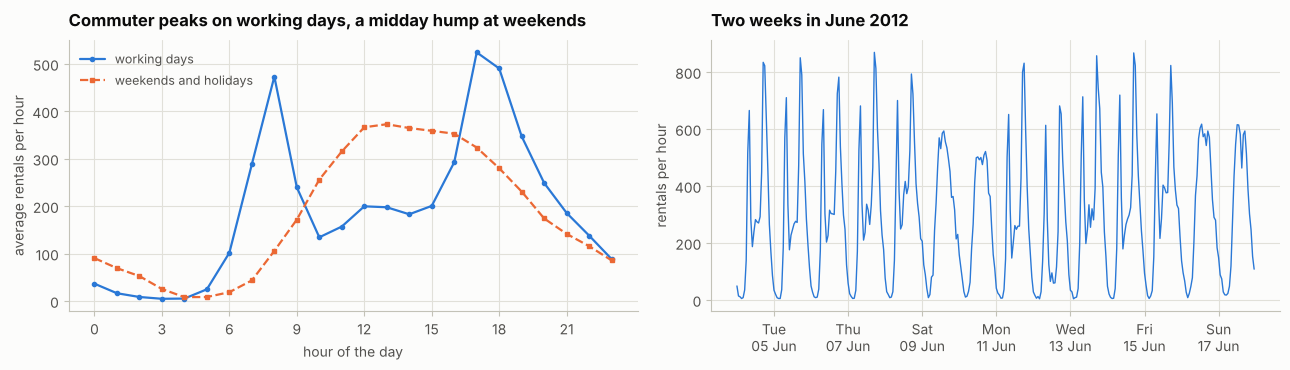

In [5]:
profile = bikes.groupby(["workingday", "hour"])["cnt"].mean().unstack(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(profile.index, profile[1], color=PALETTE[0], marker="o", markersize=3, label="working days")
axes[0].plot(profile.index, profile[0], color=PALETTE[1], marker="s", markersize=3, linestyle="--", label="weekends and holidays")
axes[0].set_xlabel("hour of the day")
axes[0].set_ylabel("average rentals per hour")
axes[0].set_xticks(range(0, 24, 3))
axes[0].legend(loc="upper left", fontsize=9)
axes[0].set_title("Commuter peaks on working days, a midday hump at weekends")
week = bikes.loc["2012-06-04":"2012-06-17", "cnt"]
axes[1].plot(week.index, week, color=PALETTE[0], linewidth=1)
axes[1].xaxis.set_major_formatter(mpl.dates.DateFormatter("%a\n%d %b"))
axes[1].set_ylabel("rentals per hour")
axes[1].set_title("Two weeks in June 2012")
fig.tight_layout()
plt.show()

On working days there are two sharp peaks, at 8 in the morning and 5 to 6 in the evening: commuters. At weekends the pattern is a single broad hump in the afternoon: leisure riders. The right panel shows the same rhythm repeating day after day, with the weekend shape on Saturdays and Sundays. Any forecast has to get this daily shape right, and it differs by type of day.

## A3. The forecasting task

Each evening at midnight, we forecast all 24 hours of the next day. That fixes what's known when the forecast is made:

- **Known**: the calendar (hour, weekday, month, holidays), and every rental count up to midnight. So for any hour of tomorrow, the same hour **yesterday** (24 hours earlier) and the same hour **last week** (168 hours earlier) are known, as are yesterday's and last week's totals, and the average of that hour over recent weeks.
- **Not known**: the actual weather. We'll use the recorded weather as a stand-in for a **weather forecast**. That's optimistic, because real forecasts make mistakes, especially about rain, so results with weather are an upper limit on what a real system would achieve. We'll show results with and without it.

The data is split by time: the models are built and compared on data up to the end of September 2012 (with July to September as the validation period), and the last quarter of 2012 is the test set, used once at the end.

In [6]:
daily_total = bikes["cnt"].resample("D").sum()
day = bikes.index.normalize()
bikes["lag_24"] = bikes["cnt"].shift(24)                 # same hour yesterday
bikes["lag_168"] = bikes["cnt"].shift(168)               # same hour last week
bikes["yesterday_total"] = day.map(daily_total.shift(1))
bikes["last_week_total"] = day.map(daily_total.rolling(7).sum().shift(1))

# For each day: the average of each hour over the previous 56 days of the same type (working day or not)
by_day = bikes.pivot_table(index=day, columns="hour", values="cnt")
day_type = bikes.groupby(day)["workingday"].first()
profile = pd.DataFrame(np.nan, index=by_day.index, columns=by_day.columns)
for k, d in enumerate(by_day.index[56:], start=56):
    previous = by_day.index[k - 56:k]
    profile.loc[d] = by_day.loc[previous[day_type[previous] == day_type[d]]].mean()
bikes["recent_profile"] = profile.stack().reindex(pd.MultiIndex.from_arrays([day, bikes["hour"]])).to_numpy()

CALENDAR = ["hour", "weekday", "month", "holiday", "workingday"]
RECENT = ["lag_24", "lag_168", "yesterday_total", "last_week_total", "recent_profile"]
WEATHER = ["temp", "atemp", "hum", "windspeed", "weathersit"]

usable = bikes.dropna(subset=RECENT)
fit = usable[:"2012-06-30"]
valid = usable["2012-07-01":"2012-09-30"]
develop = usable[:"2012-09-30"]
test = usable["2012-10-01":]
print(f"fit: {len(fit):,} hours   validation: {len(valid):,}   test: {len(test):,}")

fit: 11,784 hours   validation: 2,208   test: 2,208


Every feature uses only values from before midnight: `lag_24` for 11 pm tomorrow is 11 pm today, which is known by midnight. The daily totals are shifted by a whole day, and the **recent profile** only averages earlier days, for the same reason. The recent profile is also a forecast in its own right: "tomorrow's 8 am will look like the average 8 am of recent working days".

We deliberately leave out a "days since the start" trend feature: trees can't extrapolate it into the future (lesson section 9). The recent-history features tell the model the current level instead.

## A4. From baselines to gradient boosting

First, three baselines, then gradient boosting with more and more information. `loss="poisson"` tells the model the target is a count: it predicts on a log scale internally, which suits counts that vary from 0 at night to nearly 1,000 at rush hour, and it can never predict a negative number.

One detail matters here. With more than 10,000 rows, `HistGradientBoostingRegressor` turns on early stopping automatically, and it does so by holding out a **random** 10% of the rows. For time series that's the leaky kind of split from the lesson, so we switch it off and use a fixed number of trees.

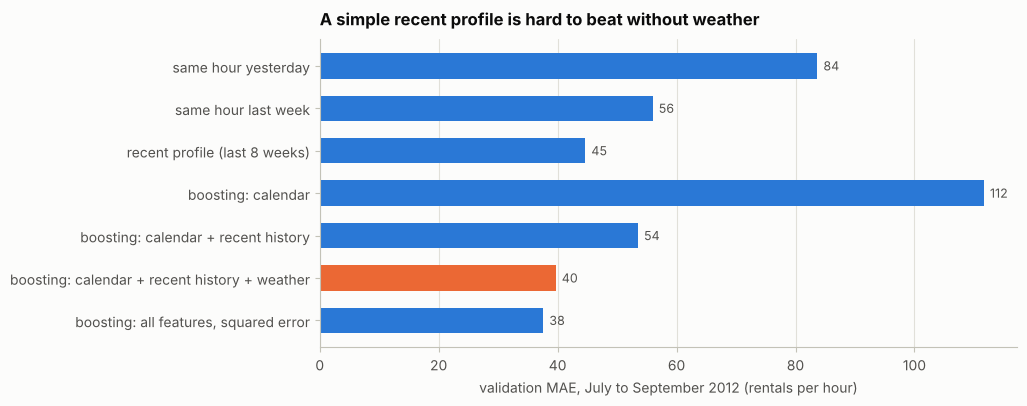

same hour yesterday                               83.7
same hour last week                               56.0
recent profile (last 8 weeks)                     44.7
boosting: calendar                               111.7
boosting: calendar + recent history               53.5
boosting: calendar + recent history + weather     39.7
boosting: all features, squared error             37.6

average rentals per hour in the validation period: 288


In [7]:
from sklearn.ensemble import HistGradientBoostingRegressor


def mae(actual, predicted):
    return float(np.mean(np.abs(np.asarray(actual) - np.asarray(predicted))))


ladder = {
    "same hour yesterday": mae(valid["cnt"], valid["lag_24"]),
    "same hour last week": mae(valid["cnt"], valid["lag_168"]),
    "recent profile (last 8 weeks)": mae(valid["cnt"], valid["recent_profile"]),
}


def boosting(loss="poisson"):
    # A fixed number of trees: automatic early stopping would hold out a RANDOM 10% of the hours, a leaky split for time series
    return HistGradientBoostingRegressor(loss=loss, max_iter=300, learning_rate=0.05, early_stopping=False, random_state=0)


for name, columns in [("calendar", CALENDAR), ("calendar + recent history", CALENDAR + RECENT),
                      ("calendar + recent history + weather", CALENDAR + RECENT + WEATHER)]:
    model = boosting().fit(fit[columns], fit["cnt"])
    ladder[f"boosting: {name}"] = mae(valid["cnt"], model.predict(valid[columns]))
squared = boosting("squared_error").fit(fit[CALENDAR + RECENT + WEATHER], fit["cnt"])
ladder["boosting: all features, squared error"] = mae(valid["cnt"], np.clip(squared.predict(valid[CALENDAR + RECENT + WEATHER]), 0, None))

ladder = pd.Series(ladder, name="validation MAE (rentals per hour)")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(ladder.index[::-1], ladder[::-1], color=[PALETTE[1] if "weather" in n else PALETTE[0] for n in ladder.index[::-1]], height=0.6)
for i, v in enumerate(ladder[::-1]):
    ax.text(v + 1, i, f"{v:.0f}", va="center", color=INK_2, fontsize=9)
ax.set_xlabel("validation MAE, July to September 2012 (rentals per hour)")
ax.grid(axis="y", visible=False)
ax.set_title("A simple recent profile is hard to beat without weather")
plt.show()
print(ladder.round(1).to_string())
print(f"\naverage rentals per hour in the validation period: {valid['cnt'].mean():.0f}")

Reading the ladder from the top:

- **"Same hour yesterday"** is a weak baseline here: it copies yesterday's weather and yesterday's type of day, so a Monday is forecast from a Sunday.
- **"Same hour last week"** fixes the type of day, and the **recent profile**, which averages eight weeks of days of the same type, is better still. It's a strong baseline: it knows the daily shape and the current level, and averaging smooths out one-off bad days.
- **Calendar features alone** are poor: they know the shape of each kind of day, but nothing about the current level of demand.
- **Adding recent history** helps a lot, but on this validation period gradient boosting with calendar and recent history still **doesn't beat the recent profile on its own**. Without new information, a more complex model has little to add to a well-chosen average.
- **Weather** is the new information that makes a difference, and with it boosting beats every baseline. Squared error does about as well as Poisson loss here (slightly better on this period); we keep Poisson, which can never forecast a negative number of rentals.

So the validation period gives a clear recommendation: use gradient boosting with all features if a weather forecast is available, and the recent profile if it isn't.

## A5. The test quarter

The choices are made: Poisson gradient boosting with all features, plus the version without weather for a realistic comparison. Refit both on all the development data (to the end of September) and forecast the last quarter of 2012:

In [8]:
final_columns = {"with weather": CALENDAR + RECENT + WEATHER, "without weather": CALENDAR + RECENT}
test_forecasts = {name: boosting().fit(develop[cols], develop["cnt"]).predict(test[cols]) for name, cols in final_columns.items()}

results = {
    "same hour yesterday": mae(test["cnt"], test["lag_24"]),
    "same hour last week": mae(test["cnt"], test["lag_168"]),
    "recent profile": mae(test["cnt"], test["recent_profile"]),
    "boosting without weather": mae(test["cnt"], test_forecasts["without weather"]),
    "boosting with weather": mae(test["cnt"], test_forecasts["with weather"]),
}
for name, value in results.items():
    print(f"{name:<26} test MAE {value:5.1f}   ({value / test['cnt'].mean():.0%} of the average hour)")

same hour yesterday        test MAE  77.2   (36% of the average hour)
same hour last week        test MAE  75.9   (35% of the average hour)
recent profile             test MAE  65.2   (30% of the average hour)
boosting without weather   test MAE  54.4   (25% of the average hour)
boosting with weather      test MAE  40.6   (19% of the average hour)


Two results to notice.

**With the weather**, gradient boosting is far better than everything else: its error is about 40% lower than the recent profile's. The weather matters much more in autumn and early winter, with cold snaps, rain and a hurricane, than in the mostly fine summer weather of the validation period.

**Without the weather**, the verdict **flipped**. On the summer validation period the recent profile won; on the autumn test quarter gradient boosting is clearly better. The profile averages the past eight weeks, so as demand falls through the autumn it keeps forecasting the higher levels of September; the boosting model's daily totals react faster. A single validation period gave a misleading recommendation. The fix is the one from the lesson: validate on **several** periods (expanding-window splits), so a choice doesn't depend on one season.

Here's one week of the test quarter, with both forecasts:

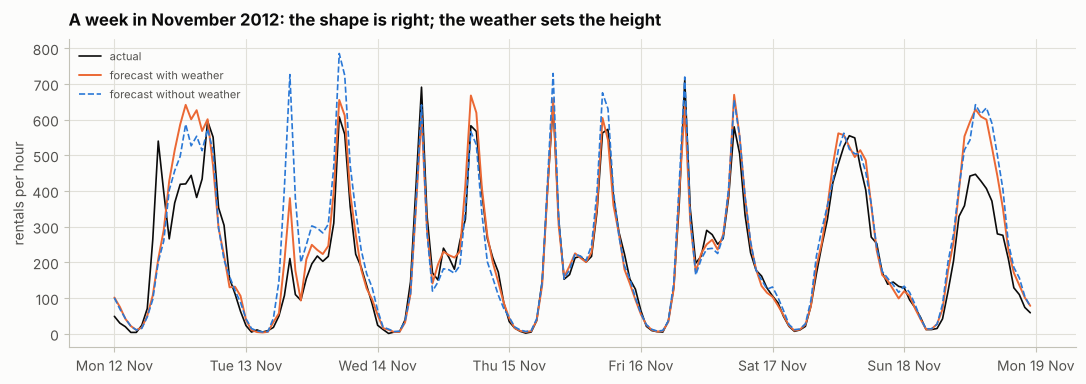

In [9]:
week = slice("2012-11-12", "2012-11-18")
mask = (test.index >= "2012-11-12") & (test.index < "2012-11-19")
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(test.index[mask], test["cnt"][mask], color=INK, linewidth=1.2, label="actual")
ax.plot(test.index[mask], test_forecasts["with weather"][mask], color=PALETTE[1], linewidth=1.4, label="forecast with weather")
ax.plot(test.index[mask], test_forecasts["without weather"][mask], color=PALETTE[0], linewidth=1.2, linestyle="--", label="forecast without weather")
ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%a %d %b"))
ax.set_ylabel("rentals per hour")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("A week in November 2012: the shape is right; the weather sets the height")
plt.show()

Both forecasts get the shape of each day right, with commuter peaks on weekdays and a broad hump at the weekend. The difference is the height of the peaks: on cold or wet days, the forecast without weather expects a normal day and overshoots.

Where are the errors largest? By hour of the day, and on the worst days:

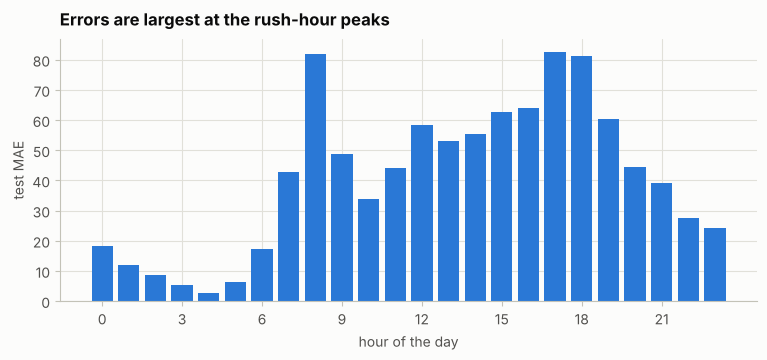

days with the largest average error:
time
2012-11-22    142.0
2012-10-29    105.0
2012-10-02    103.0
2012-11-23    102.0
2012-11-24    100.0


In [10]:
errors = pd.DataFrame({"hour": test["hour"], "error": np.abs(test["cnt"] - test_forecasts["with weather"])}, index=test.index)
by_hour = errors.groupby("hour")["error"].mean()
by_day = errors["error"].resample("D").mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(by_hour.index, by_hour, color=PALETTE[0])
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("hour of the day")
ax.set_ylabel("test MAE")
ax.set_title("Errors are largest at the rush-hour peaks")
plt.show()
print("days with the largest average error:")
print(by_day.head(5).round(0).to_string())

The errors follow the demand: large at the rush-hour peaks, tiny at night. A 10% miss at 6 pm is a bigger number than a 50% miss at 4 am. If the operator cares most about the peaks (that's when stations run out of bikes), this is the right metric; if every hour matters equally in relative terms, a percentage-type measure would be more appropriate.

The worst days are worth reading one by one:

- **Thanksgiving** (22 November) and the **two days after it**. Thanksgiving is marked as a holiday, but the model has seen only one previous Thanksgiving, and the long weekend changes behaviour on days that aren't marked at all: the Friday after counts as an ordinary working day in the data, though many commuters stayed home.
- **29 October**, when Hurricane Sandy shut the system. The weather features say "heavy rain", but nothing in the training data says "the system is closed".
- **2 October**, a day of heavy rain. The weather is recorded in only four broad categories, which can't distinguish a passing shower from a downpour.

The fix for most of these is better **information**, not a better model: calendar features for holiday periods (the days around Thanksgiving, or the Christmas week), more detailed weather such as rainfall amounts, or a list of known exceptions that an operator can override. Real forecasting systems spend a lot of effort on exactly this kind of special-day handling.

## A6. Is the weather result fair?

The forecast with weather used the **recorded** weather, which no one knows at midnight the day before. Real next-day temperature forecasts are usually accurate to within a couple of degrees, but rain timing is much less certain. So the true error of a deployed system would lie somewhere between the two forecasts, likely closer to the weather version for temperature-driven days and closer to the no-weather version for unexpected showers. To measure it properly, you'd train and test with **archived forecasts** of the weather, not recorded weather, so the model learns how much to trust them.

# Part B: What will this customer buy next?

## B1. Cleaning the transactions

Each row of the online shop data is one line of an invoice: a product, a quantity, a price, a customer and a time, from December 2010 to December 2011.

In [11]:
retail_raw.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [12]:
retail = retail_raw.copy()
steps = {"all invoice lines": len(retail)}
retail = retail[retail["CustomerID"].notna()]
steps["with a customer ID"] = len(retail)
retail = retail[~retail["InvoiceNo"].str.startswith("C")]
steps["not cancellations"] = len(retail)
retail = retail[(retail["Quantity"] > 0) & (retail["UnitPrice"] > 0)]
steps["positive quantity and price"] = len(retail)
non_products = retail.loc[~retail["StockCode"].str.match(r"^\d{5}"), "StockCode"].value_counts()
retail = retail[retail["StockCode"].str.match(r"^\d{5}")]
steps["real products only"] = len(retail)
retail["CustomerID"] = retail["CustomerID"].astype(int)

print(pd.Series(steps).to_string())
print("\nremoved non-product codes:", non_products.head(6).to_dict())
print(f"\ncustomers: {retail['CustomerID'].nunique():,}   products: {retail['StockCode'].nunique():,}")

all invoice lines              541909
with a customer ID             406829
not cancellations              397924
positive quantity and price    397884
real products only             396337

removed non-product codes: {'POST': 1099, 'M': 284, 'C2': 133, 'DOT': 16, 'BANK CHARGES': 12, 'PADS': 3}

customers: 4,334   products: 3,659


Each cleaning step has a reason:

- **No customer ID**: a quarter of the lines can't be linked to a customer, so they're useless for personal recommendations (they still count for the shop's sales, but not here).
- **Cancellations**: invoice numbers starting with "C" reverse earlier purchases.
- **Zero or negative quantities and prices**: adjustments and errors.
- **Non-products**: postage (`POST`), manual adjustments (`M`), carriage and bank charges. Real product codes start with five digits.

The result is about 396,000 purchase lines from about 4,300 customers, for about 3,700 products.

## B2. A time split, and a question to settle first

We train on everything before **1 September 2011** and test on what customers bought from then until 9 December 2011. Only customers who bought in both periods can be evaluated; the others are either gone or new.

In [13]:
cutoff = pd.Timestamp("2011-09-01")
train = retail[retail["InvoiceDate"] < cutoff]
future = retail[retail["InvoiceDate"] >= cutoff]
train_pairs = train[["CustomerID", "StockCode"]].drop_duplicates()
future_pairs = future[["CustomerID", "StockCode"]].drop_duplicates()

customers = np.sort(train["CustomerID"].unique())
products = np.sort(train["StockCode"].unique())
evaluated = np.intersect1d(customers, future_pairs["CustomerID"].unique())
new_customers = np.setdiff1d(future_pairs["CustomerID"].unique(), customers)
print(f"training customers: {len(customers):,}   products: {len(products):,}")
print(f"customers who also buy after the cutoff (evaluated): {len(evaluated):,}")
print(f"new customers after the cutoff (no history at all): {len(new_customers):,}")

bought_before = set(map(tuple, train_pairs.to_numpy()))
repeat_share = np.mean([(c, s) in bought_before for c, s in future_pairs[future_pairs["CustomerID"].isin(evaluated)].to_numpy()])
print(f"\nshare of evaluated customers' future (customer, product) pairs they had bought before: {repeat_share:.0%}")

training customers: 3,314   products: 3,388
customers who also buy after the cutoff (evaluated): 1,947
new customers after the cutoff (no history at all): 1,020



share of evaluated customers' future (customer, product) pairs they had bought before: 29%


That last number matters a lot: nearly a third of what these customers bought after the cutoff were products they'd bought before. Many of this shop's customers are small businesses that **reorder** the same products. So before building anything, we have to decide what a recommendation is for:

- **"Buy again"**: remind customers of products they're likely to reorder. Previously bought products are allowed.
- **"Discover"**: suggest products the customer has **never** bought. Previously bought products are excluded, and only new products count as hits.

Both are legitimate and both are common on real shopping sites, but they're different problems with very different scores. We'll evaluate both.

## B3. Building the purchase matrix

In [14]:
from scipy import sparse

customer_index = {c: i for i, c in enumerate(customers)}
product_index = {p: j for j, p in enumerate(products)}
R = sparse.csr_matrix((np.ones(len(train_pairs)),
                       (train_pairs["CustomerID"].map(customer_index), train_pairs["StockCode"].map(product_index))),
                      shape=(len(customers), len(products)))
print(f"matrix: {R.shape[0]:,} customers × {R.shape[1]:,} products, {R.nnz:,} purchases recorded")
print(f"filled in: {R.nnz / (R.shape[0] * R.shape[1]):.2%}")

matrix: 3,314 customers × 3,388 products, 162,426 purchases recorded
filled in: 1.45%


A 1 means "bought at least once before the cutoff", a 0 means "never bought", which isn't the same as "wouldn't like it". About 1.4% of the matrix is filled. It's stored as a **sparse** matrix, which keeps only the non-zero entries: here about 100 times less memory than a full table.

## B4. Five recommenders

- **Popular**: the products bought by the most customers before the cutoff.
- **Recently popular**: the same, counting only the last eight weeks before the cutoff, so it follows changes in what's selling.
- **Item-based**: cosine similarity between products (lesson section 13), scoring each product by its total similarity to everything the customer bought.
- **Matrix factorisation**: a truncated SVD of the purchase matrix (PCA without centring, Module 15), with 50 factors; the score is the reconstructed matrix entry.
- **Buy again**: the customer's own most frequently bought products, then popular ones to fill the list.

In [15]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

popular_counts = np.asarray(R.sum(axis=0)).ravel()
recent = train[train["InvoiceDate"] >= cutoff - pd.Timedelta(weeks=8)][["CustomerID", "StockCode"]].drop_duplicates()
recent_counts = recent["StockCode"].map(product_index).value_counts().reindex(range(len(products)), fill_value=0).to_numpy().astype(float)

item_vectors = normalize(R.T.tocsr())                       # each product as a unit-length column of buyers
item_similarity = (item_vectors @ item_vectors.T).toarray()
np.fill_diagonal(item_similarity, 0)
item_scores = np.asarray(R @ item_similarity)               # every customer's scores at once: one sparse × dense product

svd = TruncatedSVD(n_components=50, random_state=0).fit(R)
customer_factors, product_factors = svd.transform(R), svd.components_

order_counts = train.groupby(["CustomerID", "StockCode"])["InvoiceNo"].nunique()
times_bought = sparse.csr_matrix((order_counts.to_numpy().astype(float),
                                  (order_counts.index.get_level_values(0).map(customer_index),
                                   order_counts.index.get_level_values(1).map(product_index))), shape=R.shape)

scorers = {
    "popular": lambda i: popular_counts,
    "recently popular": lambda i: recent_counts + popular_counts / 1e6,       # ties broken by overall popularity
    "item-based": lambda i: item_scores[i],
    "matrix factorisation": lambda i: customer_factors[i] @ product_factors,
    "buy again": lambda i: times_bought[i].toarray().ravel() * 1e6 + popular_counts,
}
print("ready:", list(scorers))

ready: ['popular', 'recently popular', 'item-based', 'matrix factorisation', 'buy again']


Now the evaluation. For each evaluated customer, recommend 10 products and compare them with what the customer actually bought after the cutoff. In "discover" mode, products the customer had already bought are removed from both the recommendations and the targets.

In [16]:
future_sets = future_pairs[future_pairs["CustomerID"].isin(evaluated)].groupby("CustomerID")["StockCode"].apply(set)
train_sets = train_pairs.groupby("CustomerID")["StockCode"].apply(set)
K = 10


def evaluate(scorer, discover):
    precision, recall, hit, shown = [], [], [], set()
    for customer in evaluated:
        i = customer_index[customer]
        scores = np.array(scorer(i), dtype=float)
        target = future_sets[customer]
        if discover:
            already = [product_index[p] for p in train_sets[customer]]
            scores[already] = -np.inf
            target = target - train_sets[customer]
            if not target:
                continue
        top = np.argpartition(-scores, K)[:K]
        top = top[np.argsort(-scores[top])]
        recommended = {products[j] for j in top}
        shown |= recommended
        hits = len(recommended & target)
        precision.append(hits / K)
        recall.append(hits / len(target))
        hit.append(hits > 0)
    return {"customers": len(precision), "precision@10": np.mean(precision), "recall@10": np.mean(recall),
            "hit rate@10": np.mean(hit), "products shown": len(shown)}


start = time.perf_counter()
tables = {mode: pd.DataFrame({name: evaluate(s, discover=(mode == "discover")) for name, s in scorers.items()
                              if not (mode == "discover" and name == "buy again")}).T
          for mode in ["buy again allowed", "discover"]}
print(f"({time.perf_counter() - start:.0f} seconds)")
for mode, table in tables.items():
    print(f"\n{mode}:")
    print(table.round(3).to_string())

(1 seconds)

buy again allowed:
                      customers  precision@10  recall@10  hit rate@10  products shown
popular                  1947.0         0.112      0.031        0.573            10.0
recently popular         1947.0         0.118      0.031        0.523            10.0
item-based               1947.0         0.221      0.071        0.659          1281.0
matrix factorisation     1947.0         0.280      0.101        0.764           556.0
buy again                1947.0         0.340      0.137        0.838          1551.0

discover:
                      customers  precision@10  recall@10  hit rate@10  products shown
popular                  1886.0         0.049      0.017        0.333            62.0
recently popular         1886.0         0.058      0.019        0.340            62.0
item-based               1886.0         0.089      0.040        0.458           944.0
matrix factorisation     1886.0         0.104      0.048        0.523           720.0


### Reading the results

**When repeat purchases count**, **buy again** is the best: recommending each customer's own regular products finds something they bought in the following months for more than four customers in five. It needs no machine learning at all. Matrix factorisation comes second, partly because it reconstructs each customer's own purchases with high scores, so it recommends many of them too. For a shop whose customers restock, a "buy it again" list is a very useful recommendation, and any model should be compared against it.

**When only new products count**, the problem is much harder, and every score is far lower: discovering what someone will buy for the first time is genuinely difficult.

- **Popularity** is the weakest, and shows only a handful of different products to everyone.
- **Recently popular** does a little better than all-time popular: what was selling just before the cutoff is a slightly better guide than the whole year.
- **Item-based** and **matrix factorisation** roughly **double** the precision of plain popularity, and recommend hundreds of different products, so customers see suggestions matched to what they buy, not just the bestsellers.

Which to use? In practice, both: a "buy again" row for restocking and a "you might also like" row for discovery, which is exactly what many shopping sites show.

## B5. One customer's view

Numbers are abstract. Here's what the item-based recommender suggests for one customer, next to what they had bought:

In [17]:
descriptions = retail.drop_duplicates("StockCode").set_index("StockCode")["Description"]
example = evaluated[np.argsort([len(train_sets[c]) for c in evaluated])[len(evaluated) // 2]]     # a customer with a typical history
i = customer_index[example]

bought = train[train["CustomerID"] == example]["StockCode"].value_counts().sort_index().sort_values(ascending=False, kind="stable").head(10)   # ties by code
scores = scorers["item-based"](i).astype(float)
scores[[product_index[p] for p in train_sets[example]]] = -np.inf
top = np.argsort(-scores)[:8]

print(f"customer {example}: bought {len(train_sets[example])} different products before the cutoff. Most often:")
for code in bought.index:
    print(f"   {descriptions[code]}")
print("\nrecommended (never bought before), with whether they bought it after the cutoff:")
for j in top:
    print(f"   {descriptions[products[j]]:<40} {'BOUGHT' if products[j] in future_sets[example] else ''}")

customer 17092: bought 42 different products before the cutoff. Most often:
   GLITTER HANGING BUTTERFLY STRING
   FELTCRAFT PRINCESS LOLA DOLL
   FELTCRAFT PRINCESS CHARLOTTE DOLL
   FELTCRAFT PRINCESS OLIVIA DOLL
   36 PENCILS TUBE RED RETROSPOT
   COSY HOUR CIGAR BOX MATCHES
   DINOSAUR KEYRINGS ASSORTED
   KEY FOB , FRONT  DOOR
   JUMBO BAG PINK VINTAGE PAISLEY
   MODERN FLORAL STATIONERY SET

recommended (never bought before), with whether they bought it after the cutoff:
   LUNCH BAG SPACEBOY DESIGN                
   LUNCH BAG ALPHABET DESIGN                
   LUNCH BAG DOILEY PATTERN                 
   LUNCH BAG RED RETROSPOT                  
   JUMBO BAG DOILEY PATTERNS                BOUGHT
   JUMBO BAG RED RETROSPOT                  
   LUNCH BAG APPLE DESIGN                   
   SET OF 4 PANTRY JELLY MOULDS             


Some suggestions echo the customer's history: they bought a jumbo bag and red-spotted ("red retrospot") pencils, and the list suggests other jumbo bags and red retrospot items. Others, like the lunch bags, are among the shop's bestsellers, bought alongside almost everything, so they score highly for almost every customer. That's a mild form of popularity bias in item-based scores, and one reason real systems often down-weight very popular items. Only one of these eight was bought after the cutoff, which is typical: a recommendation list is a set of reasonable options, and most of them won't be taken up.

## B6. What this evaluation doesn't show

- **New customers.** Over a thousand customers made their first purchase after the cutoff. Collaborative methods can't say anything about them until they buy something; for them, recently popular products (or products related to the first item they look at) are the only option.
- **Seasonality.** The test period includes the run-up to Christmas. A model trained on a full previous year could learn that Christmas products sell in the autumn; with only nine months of history, ours can't.
- **What recommendations change.** These numbers measure whether we can predict what customers bought **without** seeing our recommendations. A real recommender changes behaviour: people buy things because they were suggested, and don't discover things that weren't. As in the lesson, only an experiment with real customers measures that.

## What we learned

**Forecasting (Part A)**

- Real series have gaps: here, missing hours meant zero rentals, and two storms shut the system.
- A **recent profile** (the average of the same hour on recent days of the same type) was a strong baseline, much better than "same hour yesterday".
- Without weather, gradient boosting lost to that simple profile on the summer validation period and beat it on the autumn test: **one validation period can mislead**. Validating on several periods gives a steadier answer.
- With weather, boosting cut the test error by about 40%, but it used recorded weather, so that's an upper limit for a real day-ahead system.
- Errors were largest at the peaks and on special days (the Thanksgiving weekend, heavy rain, a hurricane) that better calendar and weather information would partly fix.

**Recommendations (Part B)**

- Cleaning decides what's being modelled: cancellations, missing customers and non-product codes had to go.
- **Define the task first**: with repeat purchases allowed, a simple "buy again" list wins by a mile; for discovering new products, item-based filtering and matrix factorisation roughly doubled the precision of popularity and showed far more of the catalogue.
- Recent popularity beat all-time popularity, because what people buy changes over time.
- Offline evaluation can't capture new customers, seasons the model never saw, or how recommendations change behaviour.

### Ideas to go further

1. **Part A**: forecast the **casual** and **registered** riders separately (both columns are in the hourly file) and add the forecasts. Do separate models help? The two groups react very differently to weekends and weather.
2. **Part A**: add prediction intervals with quantile loss, check their coverage on the test quarter, and calibrate them with a recent window as in the lesson.
3. **Part B**: combine item-based scores with recent popularity (for example, a weighted sum of the two after scaling). Does the blend beat both in "discover" mode?
4. **Part B**: use your `als_factorise` from Exercise 11 on the purchase matrix (with zeros for products not bought, weighted less than purchases: that's the idea behind implicit-feedback ALS by Yifan Hu, Yehuda Koren and Chris Volinsky, 2008).
5. **Part B**: evaluate at several cutoffs (1 July, 1 August, 1 September) to see how stable the comparison is.

Data: Fanaee-T, H. (2013). Bike Sharing. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894. Chen, D. (2015). Online Retail. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33. Both licensed under CC BY 4.0.